# Librerias

In [2]:
!pip install -r ../requirements.txt

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing

# Carga Data

In [4]:
df_data = pd.read_csv(
    "../data/01_raw/Base.csv",
    dtype={

    },
)

In [5]:
df_data.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


In [6]:
df_data.shape

(1000000, 32)

In [7]:
df_data.dtypes

fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                     int64
has_other_cards                 

In [8]:
df_data.isna().sum()

fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

# Renombrar variables

In [9]:
df_data["month"].unique()

array([0, 1, 2, 3, 4, 5, 6, 7], dtype=int64)

In [10]:
# Quiero renombrar la variable "fraud_bool" como "target" en df_data
df_data.rename(columns={'fraud_bool': 'target'}, inplace=True)

# SUPUESTO: Month hace referencia a 2024-01 a 2024-07
df_data.rename(columns={'month': 'period'}, inplace=True)

# Unicidad - Duplicados

In [11]:
# Quiero ver los registros duplicados en df_data
df_data.duplicated().sum()

0

# Variables constantes

In [12]:
# Quiero ver las variables constantes en df_data
constant_columns = [col for col in df_data.columns if df_data[col].nunique() == 1]

constant_columns

['device_fraud_count']

# Exactitud

In [13]:
month_map = {
    0: "2024-01",
    1: "2024-02",
    2: "2024-03",
    3: "2024-04",
    4: "2024-05",
    5: "2024-06",
    6: "2024-07",
    7: "2024-08",
}

# Cambiar tipos de datos

In [14]:
df_data["period"] = pd.to_datetime(df_data["period"].map(month_map))

In [15]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,period
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,2024-01-01
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,2024-01-01
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,2024-01-01
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,2024-01-01
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,2024-01-01


In [16]:
df_data["period"].unique()

<DatetimeArray>
['2024-01-01 00:00:00', '2024-02-01 00:00:00', '2024-03-01 00:00:00',
 '2024-04-01 00:00:00', '2024-05-01 00:00:00', '2024-06-01 00:00:00',
 '2024-07-01 00:00:00', '2024-08-01 00:00:00']
Length: 8, dtype: datetime64[ns]

# Análisis de Nulos

En el diccionario se dice que algunas vars -1 significa nulo, pero algunas otras que no se especifican si es nulo generan sospechas, vamos a revisar su frecuencia para ver si podemos asumir que algunos son nulos

In [17]:
variables = [
    "prev_address_months_count", # Te dice que -1 es nulo
    "current_address_months_count", # Te dice que -1 es nulo
    "bank_months_count", # Te dice que -1 es nulo
    "session_length_in_minutes", # No te dice que -1 es nulo, pero tiene un valor negativo
    "velocity_6h", # Sospechoso que el rango sea [-175, 16818].
    "intended_balcon_amount" # Sospechoso que el rango sea  [−1, 108].
]

for var in variables:
    print("\n", var)
    print(df_data[var].value_counts().sort_index().head(10))


 prev_address_months_count
prev_address_months_count
-1     712920
 5          1
 6         53
 7        409
 8       1962
 9       5558
 10     10082
 11     11475
 12      8712
 13      4448
Name: count, dtype: int64

 current_address_months_count
current_address_months_count
-1     4254
 0     9609
 1    11297
 2    12741
 3    13986
 4    15030
 5    15896
 6    16376
 7    16270
 8    16089
Name: count, dtype: int64

 bank_months_count
bank_months_count
-1    253635
 1    194802
 2     25836
 3      8580
 4      3834
 5     28001
 6     17678
 7       931
 8        30
 9      4801
Name: count, dtype: int64

 session_length_in_minutes
session_length_in_minutes
-1.000000    2015
 0.000872       1
 0.002298       1
 0.003262       1
 0.003563       1
 0.004286       1
 0.004589       1
 0.005554       1
 0.005618       1
 0.005798       1
Name: count, dtype: int64

 velocity_6h
velocity_6h
-170.603072    1
-155.430730    1
-139.096768    1
-130.456928    1
-125.400006    1
-123.4603

Reemplazaremos como nulos en las vars prev_address_months_count, current_address_months_count y bank_months_count

In [18]:
cols_missing = [
    "prev_address_months_count",
    "current_address_months_count",
    "bank_months_count",
    "session_length_in_minutes"
]

df_data[cols_missing] = df_data[cols_missing].replace(-1, np.nan)

## Diagnostico Visual

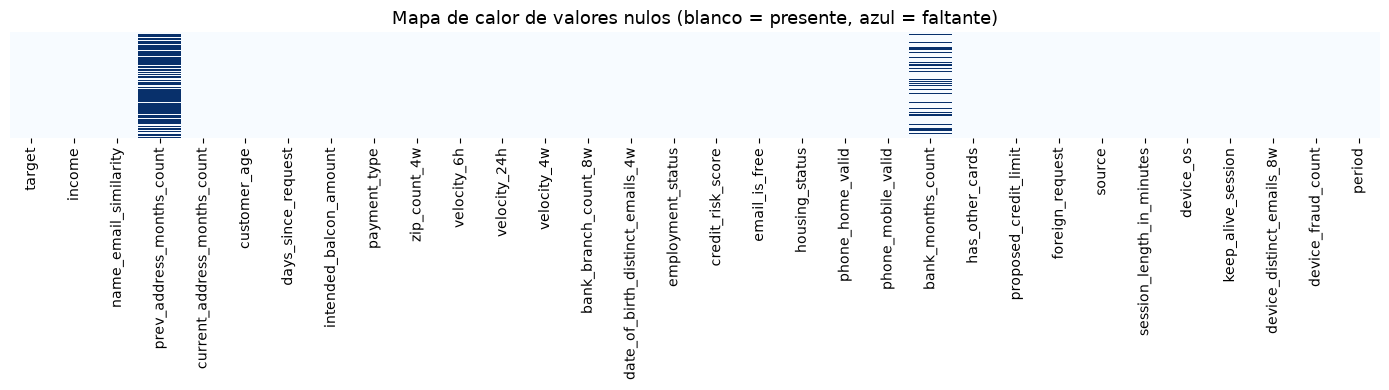

In [19]:
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(df_data.isnull(), cbar=False, yticklabels=False, ax=ax, cmap="Blues")
ax.set_title("Mapa de calor de valores nulos (blanco = presente, azul = faltante)", fontsize=13)
plt.tight_layout()
plt.show()

In [20]:
nulos = df_data.isnull().sum()
nulos = nulos[nulos > 0]
pct = (nulos / len(df_data) * 100).round(1)
print("Columna               | Nulos  | %")
print("-" * 40)
for col in nulos.index:
    print(f"{col:<22} | {nulos[col]:>5}  | {pct[col]:>4}%")

Columna               | Nulos  | %
----------------------------------------
prev_address_months_count | 712920  | 71.3%
current_address_months_count |  4254  |  0.4%
bank_months_count      | 253635  | 25.4%
session_length_in_minutes |  2015  |  0.2%


In [21]:
# Quiero ver la frecuencia de valores ascendentemente de la variable session_length_in_minutes en df_data pero solamente de los que tienen el campo source = 'TELEAPP'
df_data[df_data['source'] == 'TELEAPP']['session_length_in_minutes'].value_counts().sort_index()

session_length_in_minutes
0.037386     1
0.039325     1
0.130880     1
0.136036     1
0.149175     1
            ..
63.185905    1
68.206888    1
68.653465    1
70.496342    1
77.396428    1
Name: count, Length: 5400, dtype: int64

# Estadísticos y Percentiles

In [22]:
# ------------------------------------------
# 1) Selección de variables numéricas
# ------------------------------------------

num_cols = df_data.select_dtypes(include=[np.number]).columns.tolist()

# (Opcional) Excluir columnas numéricas que en realidad son IDs (si aplica)
# excl = ['ID_CLIENTE', 'CODIGO', ...]
# num_cols = [c for c in num_cols if c not in excl]


# ------------------------------------------
# 2) TABLA 1: Resumen estadístico
#    (Mean, Std, Min, Max, N, N Miss)
# ------------------------------------------

t1 = pd.DataFrame({
    'Variable': num_cols,
    'Label': num_cols  # En tu ejemplo el Label es igual al nombre
})

# Estadísticos principales
t1['Mean'] = [
    df_data[c].mean(skipna=True)
    for c in num_cols
]

t1['Std Dev'] = [
    df_data[c].std(skipna=True, ddof=1)
    for c in num_cols
]

t1['Minimum'] = [
    df_data[c].min(skipna=True)
    for c in num_cols
]

t1['Maximum'] = [
    df_data[c].max(skipna=True)
    for c in num_cols
]

# Conteos
t1['N'] = [
    df_data[c].notna().sum()
    for c in num_cols
]  # no nulos

t1['N Miss'] = [
    df_data[c].isna().sum()
    for c in num_cols
]  # nulos

# (Opcional) Ordenar por nombre
t1 = t1.sort_values('Variable').reset_index(drop=True)

t1

,Variable,Label,Mean,Std Dev,Minimum,Maximum,N,N Miss
0,bank_branch_count_8w,bank_branch_count_8w,184.361849,459.625329,0.000000e+00,2385.000000,1000000,0
1,bank_months_count,bank_months_count,14.862618,11.527847,1.000000e+00,32.000000,746365,253635
2,credit_risk_score,credit_risk_score,130.989595,69.681812,-1.700000e+02,389.000000,1000000,0
3,current_address_months_count,current_address_months_count,86.962058,88.409289,0.000000e+00,428.000000,995746,4254
4,customer_age,customer_age,33.689080,12.025799,1.000000e+01,90.000000,1000000,0
5,date_of_birth_distinct_emails_4w,date_of_birth_distinct_emails_4w,9.503544,5.033792,0.000000e+00,39.000000,1000000,0
6,days_since_request,days_since_request,1.025705,5.381835,4.036860e-09,78.456904,1000000,0
7,device_distinct_emails_8w,device_distinct_emails_8w,1.018312,0.180761,-1.000000e+00,2.000000,1000000,0
8,device_fraud_count,device_fraud_count,0.000000,0.000000,0.000000e+00,0.000000,1000000,0
9,email_is_free,email_is_free,0.529886,0.499106,0.000000e+00,1.000000,1000000,0


In [23]:
# ------------------------------------------
# 3) TABLA 2: Percentiles
#    (5, 10, 25, 50, 75, 90, 95, 99)
# ------------------------------------------

percentiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

q = df_data[num_cols].quantile(
    percentiles,
    interpolation='linear'
).T

# Renombrar columnas a tu formato
q = (
    q.rename(columns={
        0.05: '5th Pctl',
        0.10: '10th Pctl',
        0.25: 'Lower Quartile',
        0.50: 'Median',
        0.75: 'Upper Quartile',
        0.90: '90th Pctl',
        0.95: '95th Pctl',
        0.99: '99th Pctl'
    })
    .reset_index()
    .rename(columns={'index': 'Variable'})
)

# (Opcional) Ordenar por Variable
t2 = q.sort_values('Variable').reset_index(drop=True)

In [24]:
# ------------------------------------------
# 4) (Opcional) Formato visual tipo reporte
#    (sin cambiar valores base)
# ------------------------------------------

# Si lo quieres como en la imagen (2 decimales), crea versiones formateadas

t1_fmt = t1.copy()

for col in ['Mean', 'Std Dev', 'Minimum', 'Maximum']:
    t1_fmt[col] = t1_fmt[col].map(
        lambda x: np.nan if pd.isna(x) else round(x, 2)
    )

t2_fmt = t2.copy()

for col in [
    '5th Pctl',
    '10th Pctl',
    'Lower Quartile',
    'Median',
    'Upper Quartile',
    '90th Pctl',
    '95th Pctl',
    '99th Pctl'
]:
    t2_fmt[col] = t2_fmt[col].map(
        lambda x: np.nan if pd.isna(x) else round(x, 2)
    )

# ------------------------------------------
# 5) Mostrar / Exportar
# ------------------------------------------

# Mostrar en notebook
display(t1_fmt)
display(t2_fmt)

# Exportar a Excel (dos hojas)
#archivo = r'modelo_cancelacion_anticipada_dpf/data/08_reporting/descriptivos_universo_seleccionado_v6.xlsx'
archivo = r'../data/08_reporting/descriptivos_universo_seleccionado.xlsx'

with pd.ExcelWriter(archivo, engine='openpyxl') as writer:
    t1_fmt.to_excel(writer, sheet_name='Resumen', index=False)
    t2_fmt.to_excel(writer, sheet_name='Percentiles', index=False)

,Variable,Label,Mean,Std Dev,Minimum,Maximum,N,N Miss
0,bank_branch_count_8w,bank_branch_count_8w,184.36,459.63,0.00,2385.00,1000000,0
1,bank_months_count,bank_months_count,14.86,11.53,1.00,32.00,746365,253635
2,credit_risk_score,credit_risk_score,130.99,69.68,-170.00,389.00,1000000,0
3,current_address_months_count,current_address_months_count,86.96,88.41,0.00,428.00,995746,4254
4,customer_age,customer_age,33.69,12.03,10.00,90.00,1000000,0
5,date_of_birth_distinct_emails_4w,date_of_birth_distinct_emails_4w,9.50,5.03,0.00,39.00,1000000,0
6,days_since_request,days_since_request,1.03,5.38,0.00,78.46,1000000,0
7,device_distinct_emails_8w,device_distinct_emails_8w,1.02,0.18,-1.00,2.00,1000000,0
8,device_fraud_count,device_fraud_count,0.00,0.00,0.00,0.00,1000000,0
9,email_is_free,email_is_free,0.53,0.50,0.00,1.00,1000000,0


,Variable,5th Pctl,10th Pctl,Lower Quartile,Median,Upper Quartile,90th Pctl,95th Pctl,99th Pctl
0,bank_branch_count_8w,0.00,0.00,1.00,9.00,25.00,750.00,1463.00,1974.00
1,bank_months_count,1.00,1.00,1.00,15.00,28.00,30.00,31.00,31.00
2,credit_risk_score,28.00,48.00,83.00,122.00,178.00,226.00,255.00,305.00
3,current_address_months_count,4.00,7.00,20.00,53.00,130.00,215.00,277.00,370.00
4,customer_age,20.00,20.00,20.00,30.00,40.00,50.00,50.00,60.00
5,date_of_birth_distinct_emails_4w,2.00,4.00,6.00,9.00,13.00,16.00,19.00,23.00
6,days_since_request,0.00,0.00,0.01,0.02,0.03,0.05,6.68,22.00
7,device_distinct_emails_8w,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00
8,device_fraud_count,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
9,email_is_free,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00


# Analisis Outliers

In [25]:
# ------------------------------------------
# 1) Variables numéricas
# ------------------------------------------

num_cols = df_data.select_dtypes(
    include=[np.number]
).columns

total_rows = len(df_data)

outlier_summary = []


# ------------------------------------------
# 2) Cálculo de outliers por variable
# ------------------------------------------

for col in num_cols:

    s = df_data[col].dropna()

    # Evitar columnas constantes
    std = s.std(ddof=1)

    if std == 0 or pd.isna(std):
        outliers_count = 0
    else:
        mean = s.mean()
        z = (s - mean) / std
        outliers_count = (z.abs() > 3).sum()

    outlier_summary.append({
        'Variable': col,
        'Cantidad outliers': outliers_count,
        'Porcentaje del total de datos': f'{outliers_count / total_rows:.2%}'
    })


# ------------------------------------------
# 3) Tabla final
# ------------------------------------------

tabla_outliers = pd.DataFrame(outlier_summary)

# (Opcional) Ordenar de mayor a menor impacto
tabla_outliers = tabla_outliers.sort_values(
    'Cantidad outliers',
    ascending=False
).reset_index(drop=True)

tabla_outliers

,Variable,Cantidad outliers,Porcentaje del total de datos
0,bank_branch_count_8w,40984,4.10%
1,device_distinct_emails_8w,31933,3.19%
2,foreign_request,25242,2.52%
3,session_length_in_minutes,23571,2.36%
4,current_address_months_count,21175,2.12%
5,intended_balcon_amount,18960,1.90%
6,days_since_request,17775,1.78%
7,zip_count_4w,16247,1.62%
8,target,11029,1.10%
9,prev_address_months_count,8617,0.86%


# Desbalance de clase

In [26]:
# Contar los valores de target
target_counts = df_data['target'].value_counts()

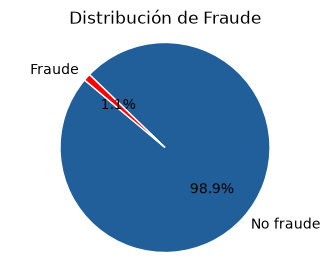


Conteo total de clases:
target
No fraude    988971
Fraude        11029
Name: count, dtype: int64


In [27]:
import matplotlib.pyplot as plt

# --- 1. Contar los valores del target en TODO el dataset ---
total_target_counts = df_data['target'].value_counts().sort_index()

# --- 2. Definir colores ---
# target = 0 -> No fraude
# target = 1 -> Fraude
colors = ['#215F9A', '#FF0000']

# --- 3. Crear el gráfico circular ---
plt.figure(figsize=(4, 3))

plt.pie(
    total_target_counts,
    labels=['No fraude', 'Fraude'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 10,
        'color': 'black'
    }
)

# --- 4. Título y formato ---
plt.title('Distribución de Fraude', fontsize=12)
plt.axis('equal')

plt.show()

# --- 5. Conteo de clases ---
print("\nConteo total de clases:")
print(
    total_target_counts.rename({
        0: 'No fraude',
        1: 'Fraude'
    })
)

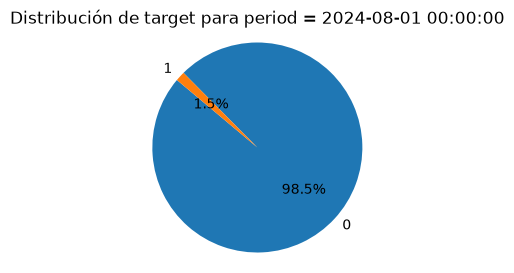

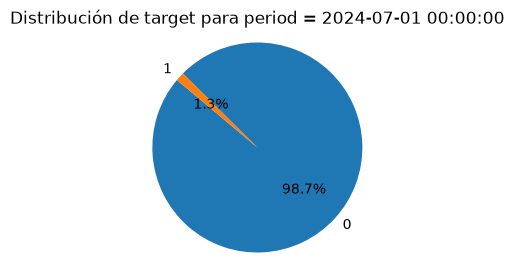

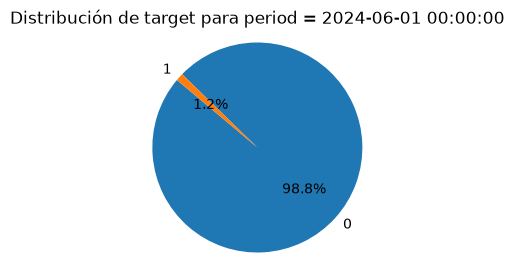

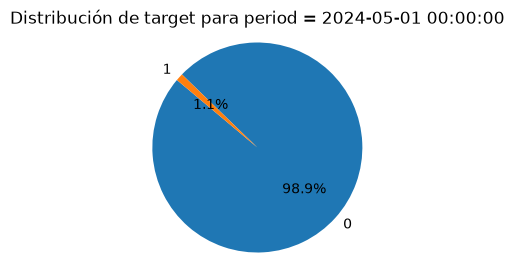

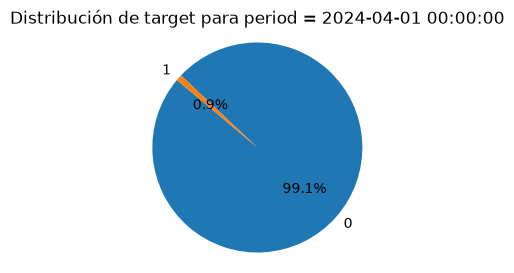

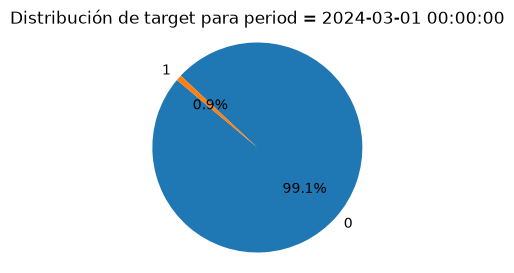

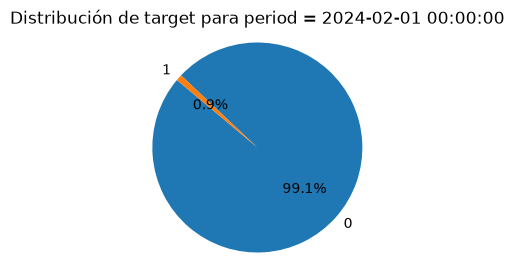

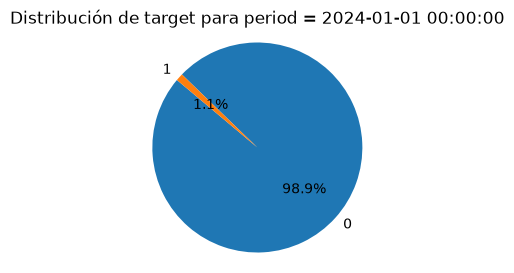

In [28]:
### Obtener los valores únicos de period y ordenarlos de forma descendente
periodos_unicos = sorted(df_data['period'].unique(), reverse=True)

# Crear un gráfico circular para cada period (en orden descendente)
for periodo in periodos_unicos:
    # Filtrar el DataFrame para el periodo actual
    df_periodo = df_data[df_data['period'] == periodo]

    # Contar los valores de target
    target_counts = df_periodo['target'].value_counts()

    # Crear el gráfico circular
    plt.figure(figsize=(4, 3))
    plt.pie(target_counts, labels=target_counts.index, autopct='%1.1f%%', startangle=140)
    plt.title(f'Distribución de target para period = {periodo}')
    plt.axis('equal')  # Asegurar que el gráfico sea un círculo

    # Mostrar el gráfico
    plt.show()

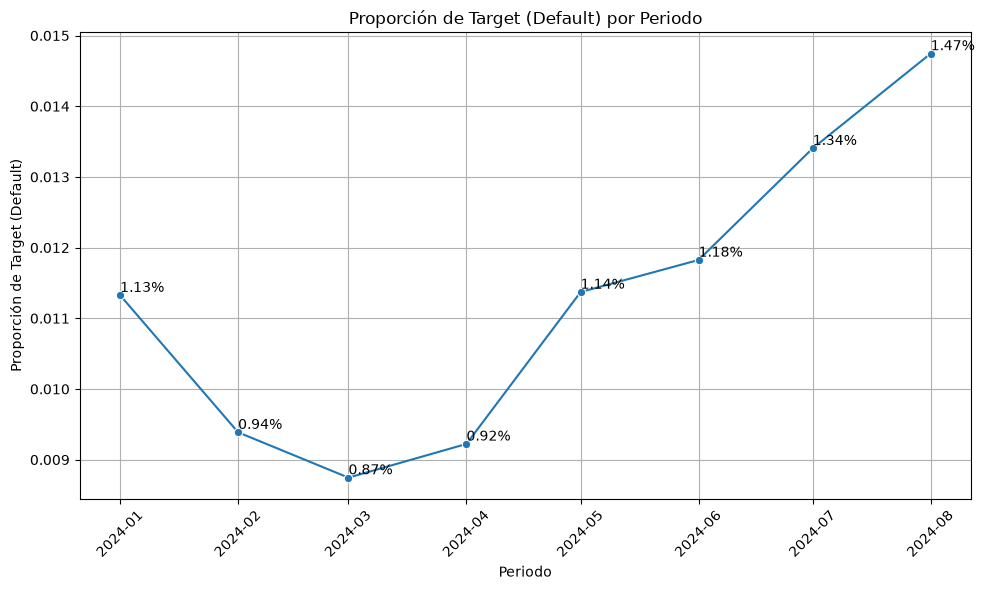

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Eliminar filas con NaT en la columna 'period' para evitar errores de graficado
df_data_cleaned = df_data.dropna(subset=['period']).copy()

# Agrupar por 'period' y calcular la media de 'target'
# La media de un target binario (0, 1) representa la proporción de 1s.
target_by_period = df_data_cleaned.groupby('period')['target'].mean().reset_index()

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))
sns.lineplot(x='period', y='target', data=target_by_period, marker='o')

# Añadir etiquetas a cada punto
for index, row in target_by_period.iterrows():
    plt.text(row['period'], row['target'], f"{row['target']:.2%}", color='black', ha="left", va="bottom")

# Añadir título y etiquetas
plt.title('Proporción de Target (Default) por Periodo')
plt.xlabel('Periodo')
plt.ylabel('Proporción de Target (Default)')

# Formatear el eje X para mostrar fechas claramente
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Imputación de Datos

In [30]:
# Vamos a asignarle a los nulos de prev_address_months_count "-1" porque parece que significa que no tuvieron dirección previa. Esto es un supuesto basado en la información que tenemos, y sería ideal confirmarlo con el equipo de datos o con la documentación del dataset.
df_data['prev_address_months_count'] = df_data['prev_address_months_count'].fillna(-1)

# Asignamos la mediana a current_address_months_count
df_data['current_address_months_count'] = df_data['current_address_months_count'].fillna(df_data['current_address_months_count'].median())

# Asignamos -1 a bank_months_count porque parece que significa que no tuvieron cuenta bancaria previa. Esto es un supuesto basado en la información que tenemos, y sería ideal confirmarlo con el equipo de datos o con la documentación del dataset.
df_data['bank_months_count'] = df_data['bank_months_count'].fillna(-1)

# Asignamos la mediana a session_length_in_minutes porque tiene un valor negativo y no parece tener sentido
df_data['session_length_in_minutes'] = df_data['session_length_in_minutes'].fillna(df_data['session_length_in_minutes'].median())   

# Guardar Dataset

In [31]:
df_data.to_csv(
    "../data/02_intermediate/Base_cleaned.csv",
    index=False
)

# Hallazgos

- Se eliminó una columna constante device_fraud_count (=0)
- No hay registros duplicados
- Se transformó la variable month a period como datetime (de 2024-01 a 202408 que fueron supuestos)
- Se identificó que algunas variables utilizaban códigos especiales (`-1`) en lugar de valores nulos. Según el diccionario y el análisis exploratorio:
  - Se mantuvo `-1` en `prev_address_months_count` y `bank_months_count` como un posible código de negocio (supuesto pendiente de validación).
  - Se imputó la mediana en `current_address_months_count` y `session_length_in_minutes`.
- Tras el preprocesamiento, el dataset no presenta valores nulos.
- El conjunto de datos presenta un fuerte desbalance de clases:
  - Transacciones legítimas: **988,971 (98.9%)**
  - Transacciones fraudulentas: **11,029 (1.1%)**